# 01 · The concept graph
**Kuizi brain walkthrough, notebook 1 of 10**

The brain does not think in "chapters". It thinks in **knowledge components** (KC): small skills
the Bac tests, such as *Dipôle RC* or *Dérivées*. Some concepts need others first: you cannot
solve an RC circuit without first-order differential equations, and those need derivatives.
Those arrows form a **directed acyclic graph** (DAG): arrows have a direction, and you can never
walk in a circle.

Why it matters: when a student fails *RLC*, Kuizi does not give harder RLC exercises. It walks
the arrows backwards to find the weak concept underneath, and sends the student there.

| In this notebook | Production ticket |
| --- | --- |
| Concept graph schema and store | T032 |
| Full Physics graph for every Bac track | T035 |
| Routing back to the weakest prerequisite | T052, T053 |

<div dir="rtl" lang="ar">

## ٠١ · خريطة المفاهيم

الدماغ لا يفكّر بـ"الفصول" بل بـ<b>المكوّنات المعرفية</b> (KC): مهارات صغيرة يمتحنها الباكالوريا، مثل
<b>ثنائي القطب RC</b> أو <b>الاشتقاق</b>. بعض المفاهيم تحتاج إلى مفاهيم قبلها: لا يمكنك حلّ دارة RC دون
المعادلات التفاضلية من الرتبة الأولى، وهذه تحتاج إلى الاشتقاق. هذه الأسهم تكوّن <b>بيانًا موجّهًا غير دوري</b> (DAG):
لكل سهم اتجاه، ولا يمكن أبدًا الدوران في حلقة.

لماذا هذا مهم؟ عندما يفشل التلميذ في RLC، لا يعطيه كويزي تمارين RLC أصعب، بل يرجع على الأسهم
ليجد المفهوم الضعيف تحته ويرسل التلميذ إليه.

</div>

In [1]:
# Concept: knowledge components and prerequisites · Production: T032, T035
import pandas as pd
from kuizi_brain import graph as G

table = pd.DataFrame(
    [(kc, fr, ar, ", ".join(pre) or "—") for kc, (fr, ar, pre) in G.PHYSICS_KCS.items()],
    columns=["id", "French name", "Arabic name", "needs first"],
)
table

,id,French name,Arabic name,needs first
0,vect,Vecteurs et repères,الأشعة والمعالم,—
1,deriv,Dérivées,الاشتقاق,—
2,eqdiff,Équations différentielles du 1er ordre,المعادلات التفاضلية من الرتبة الأولى,deriv
3,cinem,Cinématique du point,حركية النقطة المادية,"vect, deriv"
4,newton,Lois de Newton,قوانين نيوتن,cinem
5,energie,Travail et énergie,العمل والطاقة,newton
6,osc_meca,Oscillations mécaniques libres,الذبذبات الميكانيكية الحرة,"newton, energie, eqdiff"
7,rc,Dipôle RC,ثنائي القطب RC,eqdiff
8,rl,Dipôle RL,ثنائي القطب RL,eqdiff
9,rlc,Oscillations électriques libres (RLC),الذبذبات الكهربائية الحرة RLC,"rc, rl"


An order to teach the concepts: every concept comes after everything it needs. The algorithm
(Kahn's topological sort) also proves there is no cycle; if an author ever adds a circular
arrow, T034's editor refuses it with the same check.

<div dir="rtl" lang="ar">

ترتيب لتدريس المفاهيم: كل مفهوم يأتي بعد كل ما يحتاجه. الخوارزمية (الترتيب الطوبولوجي) تثبت أيضًا أنه
لا توجد حلقة؛ وإذا أضاف مؤلّف سهمًا دائريًا، يرفضه المحرّر (T034) بنفس الفحص.

</div>

In [2]:
# Concept: topological order of the DAG · Production: T032, T034
order = G.topological_order()
levels = G.depth()
for kc in order:
    print(f"level {levels[kc]}  {G.PHYSICS_KCS[kc][0]}")

level 0  Dérivées
level 0  Vecteurs et repères
level 1  Équations différentielles du 1er ordre
level 1  Cinématique du point
level 2  Dipôle RC
level 2  Dipôle RL
level 2  Lois de Newton
level 3  Oscillations électriques libres (RLC)
level 3  Travail et énergie
level 4  Oscillations mécaniques libres
level 5  Oscillations forcées
level 5  Ondes mécaniques progressives


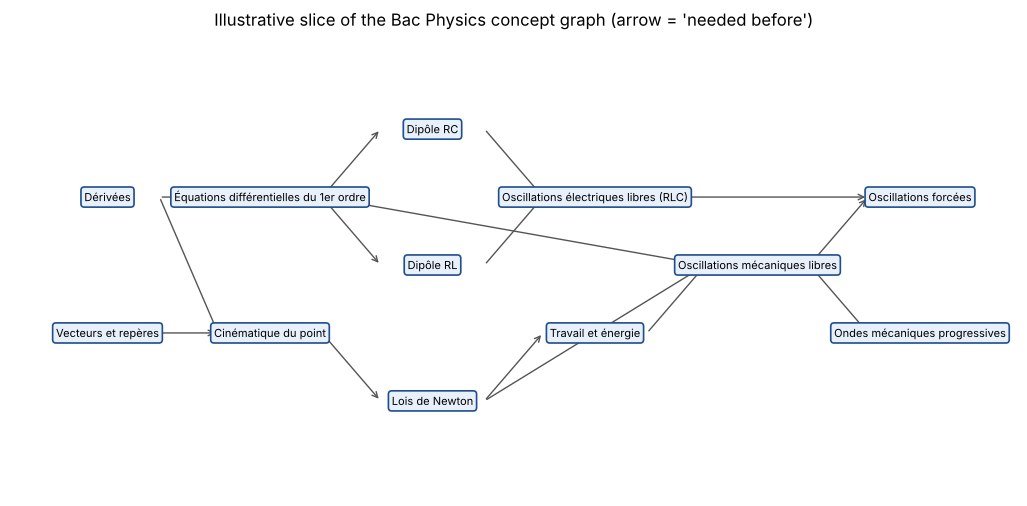

In [3]:
# Concept: drawing the concept graph · Production: T032, T177
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(13, 6))
G.draw(ax=ax)
ax.set_title("Illustrative slice of the Bac Physics concept graph (arrow = 'needed before')")
plt.show()

## A student who struggles with RLC

Imagine the brain estimates this student's **mastery** (chance of a right answer on a typical
item) for each concept. Boxes below 60 % get a dashed red border and show their value, so the
picture never relies on colour alone.

<div dir="rtl" lang="ar">

## تلميذ يجد صعوبة في RLC

لنفترض أن الدماغ قدّر <b>التمكّن</b> لهذا التلميذ (احتمال الإجابة الصحيحة على تمرين عادي) في كل مفهوم.
المفاهيم التي تحت 60% لها إطار متقطّع وتظهر قيمتها مكتوبة، فلا تعتمد الصورة على اللون وحده.

</div>

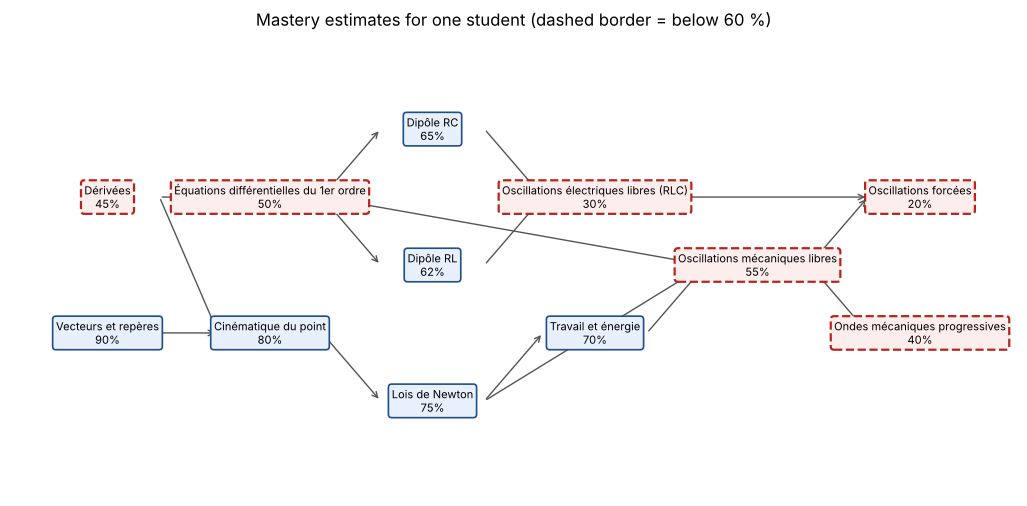

In [4]:
# Concept: mastery per concept on the graph · Production: T049, T177
mastery = {"vect": .9, "deriv": .45, "eqdiff": .5, "cinem": .8, "newton": .75, "energie": .7,
           "osc_meca": .55, "rc": .65, "rl": .62, "rlc": .3, "forcees": .2, "ondes": .4}
fig, ax = plt.subplots(figsize=(13, 6))
G.draw(mastery, ax=ax)
ax.set_title("Mastery estimates for one student (dashed border = below 60 %)")
plt.show()

In [5]:
# Concept: routing back to the weakest prerequisite · Production: T052, T053
target = "rlc"
weak = G.weakest_prerequisite(target, mastery, threshold=0.6)
print(f"The student fails {G.PHYSICS_KCS[target][0]} ({mastery[target]:.0%}).")
print(f"Deepest weak prerequisite: {G.PHYSICS_KCS[weak][0]} ({mastery[weak]:.0%}).")
print("Kuizi proposes a 1-minute remediation on it before going back to RLC.")

The student fails Oscillations électriques libres (RLC) (30%).
Deepest weak prerequisite: Dérivées (45%).
Kuizi proposes a 1-minute remediation on it before going back to RLC.


### Try it
Change the numbers in `mastery` (for example set `deriv` to 0.9) and run the two cells above
again. Which concept does Kuizi send the student to now?

### Remember
- The brain works at the level of small concepts (KCs), each linked to items.
- Prerequisite arrows form a DAG; a topological order is a valid teaching order.
- When a concept is weak, look **down** the graph before going **harder**.

<div dir="rtl" lang="ar">

### جرّب
غيّر الأرقام في <code>mastery</code> (مثلًا اجعل <code>deriv</code> يساوي 0.9) وأعد تشغيل الخليّتين أعلاه.
إلى أي مفهوم يرسل كويزي التلميذ الآن؟

### تذكّر
- الدماغ يعمل على مستوى المفاهيم الصغيرة (KC)، وكل مفهوم مرتبط بتمارين.
- أسهم المكتسبات القبلية تكوّن DAG، والترتيب الطوبولوجي ترتيب صالح للتدريس.
- عندما يكون مفهوم ضعيفًا، ابحث <b>تحته</b> في الخريطة قبل أن تذهب إلى الأصعب.

</div>